# Variação 3 — Distância por associação + Leiden
> **Modo de dados:** por padrão (`SO_DROPOUT_GRADUATE = True`, na célula de dados) a análise usa só quem evadiu ou se formou (3.630 alunos); os 794 matriculados (Enrolled) ficam de lado e são estimados no fim (seção 9). Com `False` volta às 3 classes do documento. Os números de referência do documento (4.424 alunos, 3 classes) não valem no modo padrão.
**Trabalho de Grafos · Cenário 3 (evasão e sucesso estudantil) · Modelagem – Frinhani**

**Pergunta:** que perfis de alunos existem no Grafo 1 quando a semelhança entre alunos é medida pela **distância por associação** (preset `u_dep` do pacote R `manydist`), e esses perfis são reais, estáveis e relacionados ao desfecho?

**Pipeline (igual para qualquer distância, só a distância muda):**
1. Distância por associação por janela (curso fora; desfecho nunca entra) → 2. kNN mútuo + árvore geradora mínima (MST), para ninguém ficar isolado → 3. escolha do **k** pela estabilidade (sem olhar o desfecho) → 4. **Leiden com consenso** (20 execuções; arestas que ficam juntas em <50% saem; repete até concordar) → 5. testes de permutação (NMI, V de Cramér, assortatividade; 1.000 embaralhamentos do desfecho) → 6. estabilidade (ARI entre dois consensos) → 7. perfis das comunidades.

Ambiente: `pip install igraph leidenalg scikit-learn pandas numpy scipy matplotlib`. Tempo esperado: 20–40 min em CPU (a escolha do k é a parte mais pesada; veja `RAPIDO`).

In [15]:
import os, io, zipfile, urllib.request, warnings, time, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import igraph as ig, leidenalg as la
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.metrics import adjusted_rand_score as ARI, normalized_mutual_info_score as NMI
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("figs", exist_ok=True); os.makedirs("resultados", exist_ok=True); os.makedirs("cache", exist_ok=True)

# ---- configuração ----
RAPIDO = False                       # True: menos sementes/subamostras/permutações (para testar o notebook)
K_LIST = [10, 15, 20, 30, 40, 50]
N_SEEDS, N_SUB, N_PERM, N_CONSENSO = (4, 2, 200, 8) if RAPIDO else (10, 5, 1000, 20)
COMPARAR_GOWER = True               # True: roda o mesmo pipeline com Gower para comparar (dobra o tempo)

## 1. Dados, janelas de tempo e preparação

In [16]:
# ---------- Dados ----------
url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
CSV = "data.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists(CSV):
    try:
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())); z.extract("data.csv", "data")
    except Exception as e:
        raise SystemExit("Baixe o zip do UCI 697 manualmente e coloque data.csv em data/ (separador ';'). Erro: %s" % e)

raw = pd.read_csv(CSV, sep=";")
NOMES = ["marital","app_mode","app_order","course","shift","prev_qual","prev_grade","nationality",
         "mother_qual","father_qual","mother_occ","father_occ","admission_grade","displaced",
         "special_needs","debtor","tuition_ok","gender","scholarship","age","international",
         "s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval",
         "s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval",
         "unemployment","inflation","gdp","target"]
SO_DROPOUT_GRADUATE = True   # True: só Dropout x Graduate (decisão do grupo); os "Enrolled" ficam de lado e são estimados no final.
                             # False: as 3 classes (4.424 alunos), como no documento Frinhani.
assert raw.shape == (4424, 37), raw.shape          # 4.424 alunos, 36 variáveis + desfecho
df = raw.copy(); df.columns = NOMES
y_full = df.pop("target").map({"Dropout": 0, "Enrolled": 1, "Graduate": 2}).values.astype(int)
if SO_DROPOUT_GRADUATE:
    CLASSES = ["Dropout", "Graduate"]                # 0 = Evadiu, 1 = Formou
    df_enr = df[y_full == 1].reset_index(drop=True)  # matriculados (atrasados): fora da modelagem
    df = df[y_full != 1].reset_index(drop=True)
    y = np.where(y_full[y_full != 1] == 2, 1, 0)
else:
    CLASSES = ["Dropout", "Enrolled", "Graduate"]    # 0 = Evadiu, 1 = Atrasado, 2 = Formou
    df_enr, y = None, y_full
NCLS = len(CLASSES); GRAD = NCLS - 1; N = len(df); TAG = "bin" if SO_DROPOUT_GRADUATE else "3cl"
print(f"{N} alunos na modelagem" + (f" (+ {len(df_enr)} matriculados guardados para o final)" if df_enr is not None else ""))
print(pd.Series(y).map(dict(enumerate(CLASSES))).value_counts(normalize=True).round(3))

# ---------- Janelas de tempo (Regra 1) e desfecho fora do grafo (Regra 2) ----------
CAT_BASE = ["marital","app_mode","shift","prev_qual","nationality","mother_qual","father_qual",
            "mother_occ","father_occ","displaced","special_needs","gender","international"]   # 13
NUM_BASE = ["app_order","prev_grade","admission_grade","age"]                                   # 4
CAT_FIN  = CAT_BASE + ["debtor","tuition_ok","scholarship"]                                     # 16
NUM_S1   = ["s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval"]
NUM_S2   = ["s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval"]
JANELAS = {
    "1_matricula":   (CAT_BASE, NUM_BASE),
    "2_financeiro":  (CAT_FIN,  NUM_BASE),
    "3_fim_1sem":    (CAT_FIN,  NUM_BASE + NUM_S1),
    "4_fim_2sem":    (CAT_FIN,  NUM_BASE + NUM_S1 + NUM_S2),   # só referência
}
# curso, indicadores macroeconômicos ficam FORA da distância (decisão do documento)

# categorias com < 30 alunos (na base de modelagem) viram "outros" (-1); os matriculados seguem a mesma regra
for c_ in CAT_FIN:
    vc = df[c_].value_counts(); ok = vc[vc >= 30].index
    df[c_] = df[c_].where(df[c_].isin(ok), -1)
    if df_enr is not None: df_enr[c_] = df_enr[c_].where(df_enr[c_].isin(ok), -1)

ROT = {"marital":"Estado civil","app_mode":"Modo de ingresso","app_order":"Ordem de candidatura","shift":"Turno (1=diurno, 0=noturno)",
       "prev_qual":"Qualificação anterior","prev_grade":"Nota qualif. anterior","nationality":"Nacionalidade","mother_qual":"Escolaridade da mãe",
       "father_qual":"Escolaridade do pai","mother_occ":"Ocupação da mãe","father_occ":"Ocupação do pai","admission_grade":"Nota de admissão",
       "displaced":"Deslocado","special_needs":"Necessidades especiais","debtor":"Devedor","tuition_ok":"Mensalidade em dia","gender":"Gênero",
       "scholarship":"Bolsista","age":"Idade na matrícula","international":"Internacional",
       "s1_credited":"1º sem: unid. creditadas","s1_enrolled":"1º sem: unid. inscritas","s1_evaluations":"1º sem: avaliações",
       "s1_approved":"1º sem: aprovações","s1_grade":"1º sem: nota média","s1_without_eval":"1º sem: sem avaliação",
       "s2_credited":"2º sem: unid. creditadas","s2_enrolled":"2º sem: unid. inscritas","s2_evaluations":"2º sem: avaliações",
       "s2_approved":"2º sem: aprovações","s2_grade":"2º sem: nota média","s2_without_eval":"2º sem: sem avaliação"}
def rot(txt):
    for k in sorted(ROT, key=len, reverse=True): txt = txt.replace(k, ROT[k])
    return txt

3630 alunos na modelagem (+ 794 matriculados guardados para o final)
Graduate    0.609
Dropout     0.391
Name: proportion, dtype: float64


## 2. Distância por associação
Para as categóricas, o perfil de uma categoria *c* é a distribuição das outras variáveis categóricas entre os alunos que têm *c*; a distância entre duas categorias da mesma variável é a média da variação total (TVD) entre seus perfis. As numéricas são padronizadas e rotacionadas por PCA (todos os componentes). Cada variável (ou componente) é dividida pela sua distância média, para contribuir em média com 1 (comensurabilidade); a distância final é a soma. **O desfecho nunca entra.**

**Em palavras simples.** O Gower diz que dois alunos com categorias diferentes estão sempre a distância 1 (ex.: mãe com ensino básico 2º ciclo × 3º ciclo = mãe com ensino superior). A associação pergunta: *quem tem essa categoria se parece com quem tem aquela, nas outras variáveis?* Se alunos cujas mães têm o básico 2º ciclo e o 3º ciclo são parecidos em tudo mais (turno, idade, bolsa, dívida...), essas categorias ficam **próximas**; o ensino superior, de perfil diferente, fica **longe**. Depois, cada variável é dividida pela sua distância média para ninguém dominar: sem isso uma variável com muitas categorias pesaria mais. Efeito colateral importante: **categorias raras pesam mais** (por isso necessidades especiais, nacionalidade e internacional têm peso alto) e a tabela de pesos abaixo mostra isso.

In [17]:
def deltas_associacao(cats, ref=None, d=None):
    d = df if d is None else d; ref = np.arange(len(df)) if ref is None else np.asarray(ref)
    codes = [np.asarray(pd.Categorical(d[c]).codes) for c in cats]
    Q = [int(c.max()) + 1 for c in codes]; nvar = len(cats); pos = np.cumsum([0] + Q)
    Z = np.zeros((len(ref), sum(Q)))
    for j, c in enumerate(codes): Z[np.arange(len(ref)), pos[j] + c[ref]] = 1
    zm = Z.sum(0); ZZ = Z.T @ Z; np.fill_diagonal(ZZ, 0)
    P = ZZ / np.maximum(zm[:, None], 1)               # linha = perfil da categoria nas outras variáveis
    deltas = [np.abs(P[pos[j]:pos[j+1], None, :] - P[None, pos[j]:pos[j+1], :]).sum(-1) / (2 * (nvar - 1))
              for j in range(nvar)]
    return codes, deltas

def associacao(cats, nums, ref=None, d=None):
    # d: tabela de alunos (padrão: df); ref: linhas usadas para estimar perfis, frequências e PCA (padrão: todos os de df)
    d = df if d is None else d; n = len(d); ref = np.arange(len(df)) if ref is None else np.asarray(ref)
    D = np.zeros((n, n)); codes, deltas = deltas_associacao(cats, ref, d); pesos = {}
    for v, c, dl in zip(cats, codes, deltas):           # categóricas, comensuráveis
        f = np.bincount(c[ref], minlength=len(dl)) / len(ref)
        m = f @ dl @ f
        if m <= 0: continue                              # variável constante (uma só categoria): não contribui
        pesos[v] = 1 / m
        D += dl[c[:, None], c[None, :]] / m
    X = d[nums].to_numpy(float)                        # numéricas: padroniza + PCA completo
    X = (X - X[ref].mean(0)) / X[ref].std(0, ddof=1)
    X = X @ np.linalg.svd(X[ref], full_matrices=False)[2].T
    for k in range(X.shape[1]):
        dk = np.abs(X[:, k][:, None] - X[:, k][None, :]); D += dk / dk[np.ix_(ref, ref)].mean()
    return D.astype(np.float32), pesos

def gower(cats, nums, chunk=600):                       # só para a comparação opcional
    Cc = df[cats].values; X = df[nums].values.astype(np.float32)
    rang = X.max(0) - X.min(0); rang[rang == 0] = 1; X = X / rang
    p = len(cats) + len(nums); D = np.zeros((N, N), dtype=np.float32)
    for i in range(0, N, chunk):
        s = slice(i, i + chunk)
        D[s] = (np.abs(X[s, None, :] - X[None, :, :]).sum(-1) + (Cc[s, None, :] != Cc[None, :, :]).sum(-1)) / p
    return D

def carrega(nome_dist, fn):
    cache = {}
    for j, (cats, nums) in JANELAS.items():
        arq = f"cache/D_{nome_dist}_{TAG}_{j}.npy"
        if os.path.exists(arq): cache[j] = np.load(arq)
        else:
            t = time.time(); cache[j] = fn(cats, nums); np.save(arq, cache[j]); print(nome_dist, j, f"{time.time()-t:.0f}s")
    return cache

DIST_ASSOC = carrega("assoc", lambda c, n: associacao(c, n)[0])

# checagens rápidas
for j, D in DIST_ASSOC.items():
    assert np.allclose(D, D.T, atol=1e-4) and np.allclose(np.diag(D), 0, atol=1e-4), j
_, pesos = associacao(*JANELAS["3_fim_1sem"])
print("Peso de cada variável categórica na distância (1 / distância média entre categorias; Gower = 1 para todas):")
display(pd.Series(pesos).round(2).sort_values(ascending=False).to_frame("peso"))

Peso de cada variável categórica na distância (1 / distância média entre categorias; Gower = 1 para todas):


,peso
special_needs,488.03
international,115.36
nationality,106.00
debtor,48.18
tuition_ok,32.69
gender,30.43
shift,25.82
scholarship,21.28
marital,20.92
displaced,18.78


> Conferência opcional contra o pacote oficial: o documento do grupo reporta correlação 1,000 com `manydist` 0.5.1 (R 4.5+) numa amostra de 500 alunos. Se o grupo já tem `validacao_amostra.py` / `validacao_manydist.R`, basta reutilizar; este notebook usa a mesma lógica da reimplementação.

## 3. Grafo: kNN mútuo + MST
A aresta i–j existe se j está entre os k vizinhos mais próximos de i **e** vice-versa. A MST (calculada sobre o grafo dos 50 vizinhos mais próximos) garante que nenhum aluno fique isolado. Peso da aresta = semelhança, `1 − d/d_max`.

In [18]:
def arestas(D, k):
    n = len(D); Dm = D.astype(np.float32).copy(); np.fill_diagonal(Dm, np.inf)
    nn = np.argpartition(Dm, k, axis=1)[:, :k]
    A = np.zeros((n, n), dtype=bool); A[np.repeat(np.arange(n), k), nn.ravel()] = True
    M = A & A.T
    kk = min(50, n - 1); nn50 = np.argpartition(Dm, kk, axis=1)[:, :kk]
    r = np.repeat(np.arange(n), kk); c = nn50.ravel()
    S = csr_matrix((Dm[r, c] + 1e-6, (r, c)), shape=(n, n))
    mst = minimum_spanning_tree(S).tocoo()
    M[mst.row, mst.col] = True; M[mst.col, mst.row] = True
    i, j = np.where(np.triu(M, 1)); return i, j

def peso(D, i, j): return np.maximum(1 - D[i, j] / D.max(), 1e-3)

def grafo(n, i, j, w):
    g = ig.Graph(n=n, edges=list(zip(i.tolist(), j.tolist()))); g.es["weight"] = w.tolist(); return g

def leiden(g, seed=0):
    return np.array(la.find_partition(g, la.ModularityVertexPartition, weights="weight",
                                      seed=seed, n_iterations=-1).membership)

def consenso(g, n_runs=N_CONSENSO, seed0=0, max_iter=10):
    # Leiden n_runs vezes; arestas que ficam juntas em <50% das execuções saem; repete até as execuções concordarem
    for it in range(max_iter):
        runs = np.array([leiden(g, seed0 + s) for s in range(n_runs)])
        concorda = np.mean([ARI(runs[0], r) for r in runs[1:]])
        E = np.array(g.get_edgelist()); co = (runs[:, E[:, 0]] == runs[:, E[:, 1]]).mean(0)
        if concorda > 0.99 or (co >= 0.5).all() and it > 0: break
        g = g.subgraph_edges(np.where(co >= 0.5)[0].tolist(), delete_vertices=False)
    return runs[0]

## 4. Escolha do k pela estabilidade (sem olhar o desfecho)
Para cada k: (a) ARI médio entre partições do Leiden com várias sementes; (b) ARI entre a partição completa e a de subamostras de 90% dos alunos (nos alunos em comum). O k escolhido é o de maior média entre (a) e (b). **É a etapa mais demorada** — o resultado fica salvo em `cache/`.

k escolhido (associação): {'1_matricula': 40, '2_financeiro': 20, '3_fim_1sem': 20, '4_fim_2sem': 50}


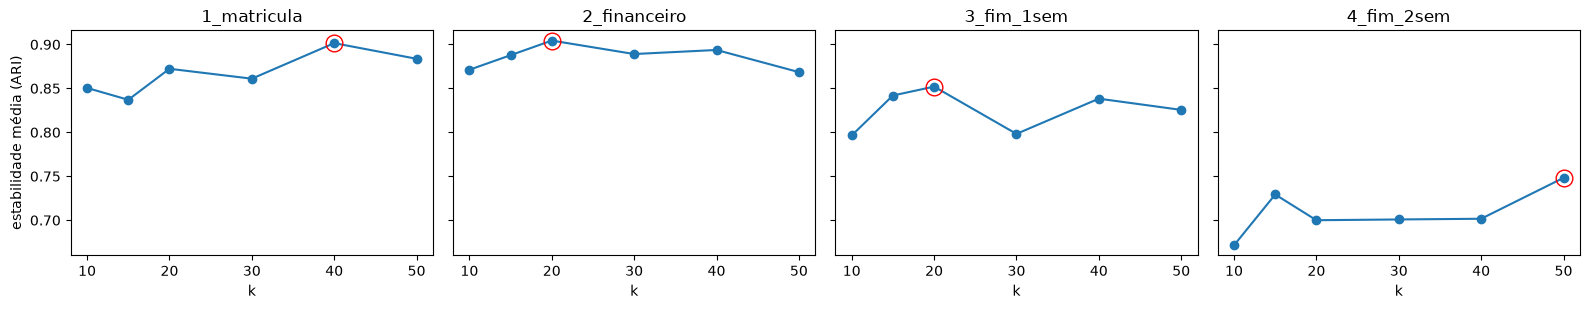

In [19]:
def estabilidade(D, k, n_seeds=N_SEEDS, n_sub=N_SUB):
    n = len(D); i, j = arestas(D, k); g = grafo(n, i, j, peso(D, i, j))
    parts = [leiden(g, s) for s in range(n_seeds)]
    a = np.mean([ARI(parts[p], parts[q]) for p in range(n_seeds) for q in range(p + 1, n_seeds)])
    rs = np.random.default_rng(SEED); subs = []
    for _ in range(n_sub):
        idx = np.sort(rs.choice(n, int(0.9 * n), replace=False)); Ds = D[np.ix_(idx, idx)]
        ii, jj = arestas(Ds, k); gs = grafo(len(idx), ii, jj, peso(Ds, ii, jj))
        subs.append(ARI(parts[0][idx], leiden(gs, 0)))
    b = np.mean(subs)
    return dict(k=k, ari_sementes=a, ari_subamostra=b, media=(a + b) / 2, arestas=len(i))

def escolhe_k(DIST, nome_dist):
    arq = f"cache/k_{nome_dist}_{TAG}.pkl"
    if os.path.exists(arq): return pickle.load(open(arq, "rb"))
    out = {}
    for jan in JANELAS:
        t = time.time(); out[jan] = pd.DataFrame([estabilidade(DIST[jan], k) for k in K_LIST]); print(nome_dist, jan, f"{time.time()-t:.0f}s")
    pickle.dump(out, open(arq, "wb")); return out

EST_A = escolhe_k(DIST_ASSOC, "assoc")
K_A = {jan: int(t.loc[t["media"].idxmax(), "k"]) for jan, t in EST_A.items()}
print("k escolhido (associação):", K_A)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for a, (jan, t) in zip(ax, EST_A.items()):
    a.plot(t["k"], t["media"], "o-"); kk = K_A[jan]; a.plot(kk, t.set_index("k").loc[kk, "media"], "o", ms=12, mfc="none", mec="r")
    a.set_title(jan); a.set_xlabel("k")
ax[0].set_ylabel("estabilidade média (ARI)"); plt.tight_layout(); plt.savefig("figs/var3_estabilidade_k.png", dpi=150); plt.show()

## 5. Leiden com consenso, separação e estabilidade
* **Separação:** NMI entre comunidades e desfecho **menos** o NMI médio com o desfecho embaralhado (1.000 vezes). Também V de Cramér (comunidades ≥ 30 alunos) e assortatividade nominal do desfecho no grafo, cada um com p-valor de permutação (o menor possível com 1.000 permutações é 0,001).
* **Estabilidade:** ARI entre dois consensos com sementes diferentes.

In [20]:
def cramer_v(memb, yy, minimo=30):
    ids, cont = np.unique(memb, return_counts=True); keep = ids[cont >= minimo]
    m = np.isin(memb, keep); idx = np.searchsorted(keep, memb[m])
    T = np.bincount(idx * NCLS + yy[m], minlength=len(keep) * NCLS).reshape(-1, NCLS).astype(float)
    T = T[:, T.sum(0) > 0]; n = T.sum(); e = T.sum(1, keepdims=True) @ T.sum(0, keepdims=True) / n
    chi2 = ((T - e) ** 2 / e).sum(); return np.sqrt(chi2 / (n * (min(T.shape) - 1)))

def separacao(g, memb, n_perm=N_PERM):
    rs = np.random.default_rng(SEED)
    nmi_r, v_r, a_r = NMI(memb, y), cramer_v(memb, y), g.assortativity_nominal(y.tolist(), directed=False)
    nmi_n, v_n, a_n = [], [], []
    for _ in range(n_perm):
        yp = rs.permutation(y); nmi_n.append(NMI(memb, yp)); v_n.append(cramer_v(memb, yp)); a_n.append(g.assortativity_nominal(yp.tolist(), directed=False))
    p = lambda r, nul: (1 + np.sum(np.array(nul) >= r)) / (1 + len(nul))
    return dict(NMI=nmi_r, NMI_ajustado=nmi_r - np.mean(nmi_n), p_NMI=p(nmi_r, nmi_n),
                V_Cramer=v_r, V_max_nulo=max(v_n), p_V=p(v_r, v_n),
                assortatividade=a_r, assort_max_nulo=max(a_n), p_assort=p(a_r, a_n))

def roda(DIST, K, nome_dist):
    arq = f"cache/res_{nome_dist}_{TAG}.pkl"
    if os.path.exists(arq): return pickle.load(open(arq, "rb"))
    out = {}
    for jan in JANELAS:
        t = time.time(); D, k = DIST[jan], K[jan]
        i, j = arestas(D, k); g = grafo(N, i, j, peso(D, i, j))
        m1, m2 = consenso(g, seed0=0), consenso(g, seed0=100)
        tam = np.bincount(m1)
        r = dict(k=k, arestas=len(i), comunidades_ge30=int((tam >= 30).sum()), cobertura=tam[tam >= 30].sum() / N,
                 modularidade=g.modularity(m1.tolist(), weights="weight"), estabilidade_ARI=ARI(m1, m2))
        r.update(separacao(g, m1)); out[jan] = dict(memb=m1, edges=(i, j), metricas=r); print(nome_dist, jan, f"{time.time()-t:.0f}s")
    pickle.dump(out, open(arq, "wb")); return out

RES_A = roda(DIST_ASSOC, K_A, "assoc")
tab = pd.DataFrame({jan: r["metricas"] for jan, r in RES_A.items()}).T
display(tab.round(3)); tab.to_csv("resultados/var3_associacao_leiden_metricas.csv")

,k,arestas,comunidades_ge30,cobertura,modularidade,estabilidade_ARI,NMI,NMI_ajustado,p_NMI,V_Cramer,V_max_nulo,p_V,assortatividade,assort_max_nulo,p_assort
1_matricula,40.0,41834.0,16.0,0.994,0.841,0.978,0.038,0.036,0.001,0.343,0.106,0.001,0.166,0.022,0.001
2_financeiro,20.0,20554.0,22.0,1.000,0.889,0.991,0.083,0.081,0.001,0.522,0.110,0.001,0.345,0.026,0.001
3_fim_1sem,20.0,18434.0,23.0,1.000,0.858,0.938,0.107,0.105,0.001,0.585,0.120,0.001,0.552,0.029,0.001
4_fim_2sem,50.0,39896.0,14.0,1.000,0.773,0.890,0.138,0.137,0.001,0.617,0.099,0.001,0.606,0.020,0.001


## 6. Perfis das comunidades (≥ 30 alunos)
Para cada comunidade: tamanho, composição do desfecho e o que a caracteriza (variáveis numéricas em desvios-padrão da média geral; categorias com ≥ 50% de presença e lift ≥ 1,3 sobre a base).

In [21]:
def perfil(memb, jan, minimo=30):
    cats, nums = JANELAS[jan]; z = (df[nums] - df[nums].mean()) / df[nums].std(); rows = []
    base = {v: df[v].value_counts(normalize=True) for v in cats}
    for c in np.unique(memb):
        m = memb == c
        if m.sum() < minimo: continue
        zc = z[m].mean(); zc = zc.reindex(zc.abs().sort_values(ascending=False).index).head(3)
        cat = []
        for v in cats:
            s = df.loc[m, v].value_counts(normalize=True)
            for val, sh in s.items():
                if sh >= 0.5 and sh / base[v][val] >= 1.3: cat.append((sh, f"{v}={val} ({sh:.0%})"))
        cat = [t for _, t in sorted(cat, reverse=True)[:3]]
        rows.append(dict(comunidade=c, alunos=int(m.sum()), evasao=(y[m] == 0).mean(),
                         atrasado=(y[m] == 1).mean() if NCLS == 3 else 0.0, formou=(y[m] == GRAD).mean(), numericas="; ".join(f"{k} {v:+.1f}dp" for k, v in zc.items()),
                         categoricas="; ".join(cat)))
    return pd.DataFrame(rows).sort_values("evasao", ascending=False).reset_index(drop=True)

def rotulo_curto(memb, jan, c, minimo=30):
    # frase curta com a característica mais marcante da comunidade c (maior |z| numérico, ou maior lift categórico)
    cats, nums = JANELAS[jan]; m = memb == c
    if m.sum() < minimo: return ""
    z = (df[nums] - df[nums].mean()) / df[nums].std(); zc = z[m].mean()
    melhor_num = zc.abs().idxmax(); cand = [(abs(zc[melhor_num]), f"{rot(melhor_num)} {zc[melhor_num]:+.1f}dp")]
    for v in cats:
        s_ = df.loc[m, v].value_counts(normalize=True); base_v = df[v].value_counts(normalize=True)
        for val, sh in s_.items():
            if sh >= 0.5:
                lift = sh / base_v[val]
                if lift >= 1.3: cand.append((lift, f"{rot(v)}={val} ({sh:.0%})"))
    cand.sort(key=lambda t: -t[0]); return cand[0][1] if cand else ""

PERFIS = {}
for jan in ["1_matricula", "3_fim_1sem"]:
    PERFIS[jan] = perfil(RES_A[jan]["memb"], jan); print("\n===", jan, "===")
    display(PERFIS[jan].style.format({"evasao": "{:.0%}", "atrasado": "{:.0%}", "formou": "{:.0%}"}))
    PERFIS[jan].to_csv(f"resultados/var3_perfis_{jan}.csv", index=False)

# comunidades de alto risco na matrícula
pm = PERFIS["1_matricula"]; alto = pm[pm["evasao"] >= 0.5]
if len(alto):
    print(f"\nMatrícula: {len(alto)} comunidades com evasão ≥ 50%, {alto['alunos'].sum()} alunos "
          f"({alto['alunos'].sum()/N:.0%}), evasão média ponderada = {np.average(alto['evasao'], weights=alto['alunos']):.0%}")
else:
    print("\nMatrícula: nenhuma comunidade com evasão ≥ 50%.")


=== 1_matricula ===


,comunidade,alunos,evasao,atrasado,formou,numericas,categoricas
0,10,163,67%,0%,33%,age +0.5dp; admission_grade -0.3dp; app_order -0.1dp,mother_occ=0 (77%); mother_qual=34 (69%); father_occ=0 (64%)
1,4,267,62%,0%,38%,age +0.5dp; app_order -0.5dp; admission_grade -0.4dp,displaced=0 (73%); app_mode=39 (57%); gender=1 (55%)
2,7,203,62%,0%,38%,age +0.7dp; app_order -0.5dp; admission_grade +0.2dp,displaced=0 (66%)
3,5,235,60%,0%,40%,age +1.6dp; app_order -0.5dp; prev_grade -0.1dp,displaced=0 (84%); marital=2 (74%); app_mode=39 (68%)
4,6,205,54%,0%,46%,age +0.8dp; app_order -0.5dp; prev_grade -0.2dp,shift=0 (100%); displaced=0 (81%)
5,2,397,45%,0%,55%,app_order +0.5dp; age -0.5dp; prev_grade -0.2dp,gender=1 (100%); displaced=1 (97%); app_mode=1 (54%)
6,11,155,44%,0%,56%,age +1.9dp; app_order -0.5dp; admission_grade +0.1dp,shift=0 (100%); displaced=0 (84%); marital=2 (77%)
7,15,32,44%,0%,56%,app_order -0.4dp; admission_grade -0.4dp; prev_grade +0.3dp,nationality=41 (100%); international=1 (100%); mother_occ=9 (53%)
8,14,39,44%,0%,56%,age -0.3dp; app_order +0.3dp; admission_grade -0.1dp,special_needs=1 (100%); app_mode=1 (51%)
9,12,139,42%,0%,58%,admission_grade +0.9dp; app_order -0.6dp; prev_grade +0.5dp,prev_qual=39 (99%); app_mode=44 (93%); gender=1 (54%)



=== 3_fim_1sem ===


,comunidade,alunos,evasao,atrasado,formou,numericas,categoricas
0,10,144,99%,0%,1%,s1_grade -2.1dp; s1_approved -1.5dp; s1_evaluations -0.8dp,gender=1 (52%)
1,13,120,93%,0%,7%,s1_approved -0.9dp; s1_grade -0.9dp; admission_grade -0.4dp,tuition_ok=0 (99%); gender=1 (57%)
2,4,252,92%,0%,8%,s1_approved -0.6dp; age +0.6dp; s1_grade -0.5dp,debtor=1 (96%); tuition_ok=0 (80%); displaced=0 (66%)
3,14,117,74%,0%,26%,age +1.1dp; s1_grade -0.6dp; admission_grade -0.4dp,scholarship=0 (97%); father_qual=34 (79%); mother_qual=34 (79%)
4,7,181,57%,0%,43%,age +0.8dp; app_order -0.5dp; s1_approved -0.2dp,displaced=0 (77%); app_mode=39 (64%); gender=1 (52%)
5,6,186,55%,0%,45%,age +1.6dp; app_order -0.5dp; s1_credited +0.3dp,displaced=0 (83%); marital=2 (78%); app_mode=39 (66%)
6,12,139,50%,0%,50%,s1_enrolled -2.5dp; s1_grade -2.1dp; s1_evaluations -1.9dp,displaced=1 (81%); app_mode=1 (68%); gender=1 (56%)
7,1,306,44%,0%,56%,age +1.2dp; app_order -0.5dp; s1_credited +0.4dp,shift=0 (100%); displaced=0 (82%); father_qual=37 (57%)
8,22,32,44%,0%,56%,app_order -0.4dp; admission_grade -0.4dp; prev_grade +0.3dp,nationality=41 (100%); international=1 (100%); mother_occ=9 (53%)
9,21,40,42%,0%,57%,s1_enrolled -0.4dp; s1_evaluations -0.3dp; age -0.3dp,special_needs=1 (100%)



Matrícula: 5 comunidades com evasão ≥ 50%, 1073 alunos (30%), evasão média ponderada = 61%


## 7. Gráficos para o artigo/slides

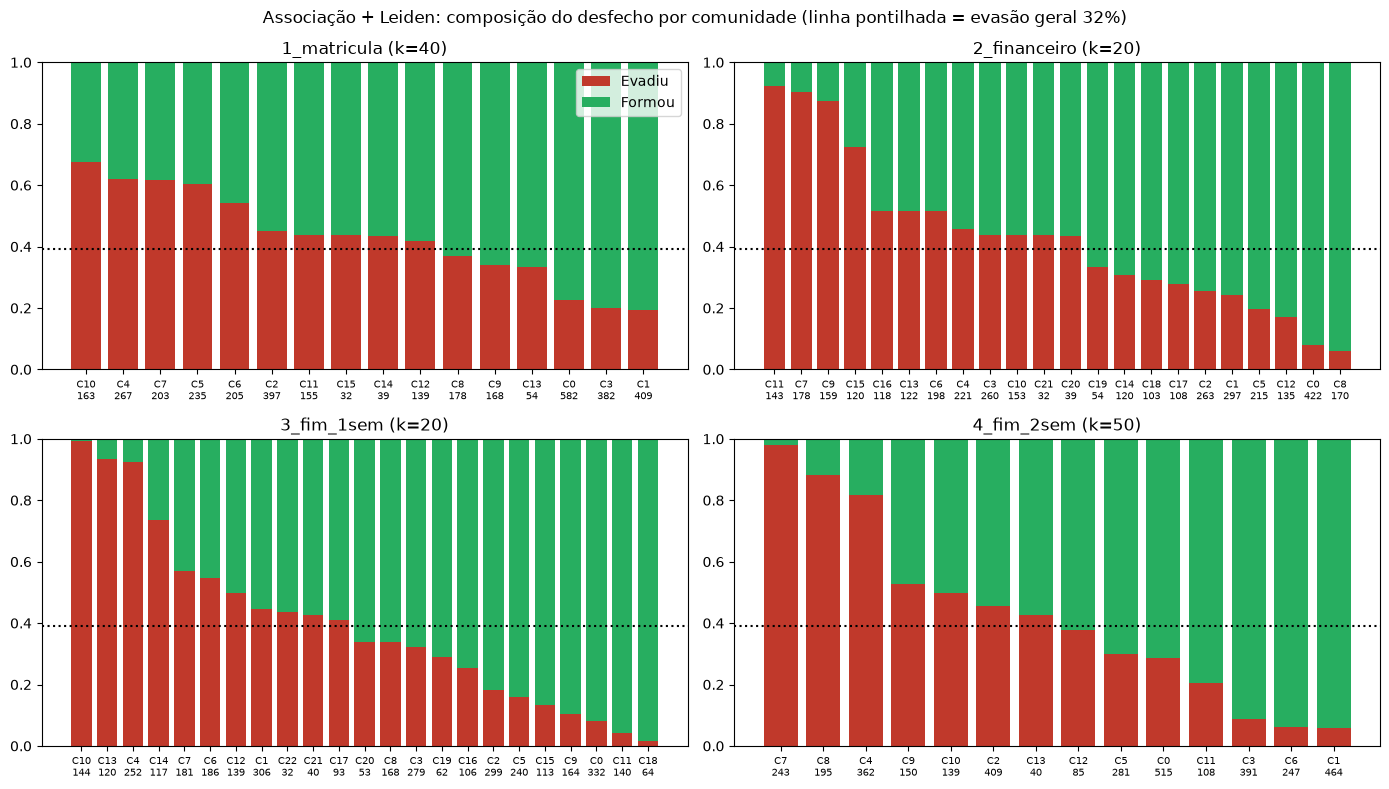

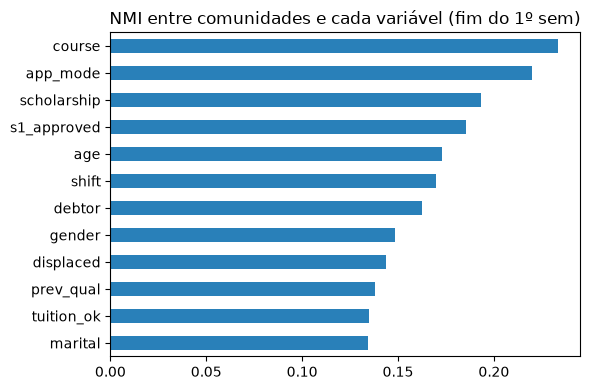

In [22]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
for ax, jan in zip(axs.ravel(), JANELAS):
    memb = RES_A[jan]["memb"]; p = perfil(memb, jan).sort_values("evasao", ascending=False)
    x = np.arange(len(p)); ax.bar(x, p["evasao"], label="Evadiu", color="#c0392b")
    if NCLS == 3: ax.bar(x, p["atrasado"], bottom=p["evasao"], label="Atrasado", color="#f1c40f")
    ax.bar(x, p["formou"], bottom=p["evasao"] + p["atrasado"], label="Formou", color="#27ae60")
    ax.axhline((y == 0).mean(), ls=":", color="k"); ax.set_xticks(x); ax.set_xticklabels([f"C{c}\n{n}" for c, n in zip(p["comunidade"], p["alunos"])], fontsize=7)
    ax.set_title(f"{jan} (k={K_A[jan]})"); ax.set_ylim(0, 1)
axs[0, 0].legend(loc="upper right"); fig.suptitle("Associação + Leiden: composição do desfecho por comunidade (linha pontilhada = evasão geral 32%)")
plt.tight_layout(); plt.savefig("figs/var3_composicao_desfecho.png", dpi=150); plt.show()

# o que organiza as comunidades (fim do 1º semestre): NMI comunidade x variável
jan = "3_fim_1sem"; memb = RES_A[jan]["memb"]; cats, nums = JANELAS[jan]
nmi_var = {v: NMI(memb, df[v]) for v in cats + ["course"]}
for v in nums: nmi_var[v] = NMI(memb, pd.qcut(df[v], 5, duplicates="drop").cat.codes)
s = pd.Series(nmi_var).sort_values(ascending=False).head(12)
s.iloc[::-1].plot.barh(figsize=(6, 4), color="#2980b9"); plt.title("NMI entre comunidades e cada variável (fim do 1º sem)")
plt.tight_layout(); plt.savefig("figs/var3_nmi_variaveis.png", dpi=150); plt.show()

### Grafo colorido por comunidade e por desfecho
Três painéis: (1) o Grafo 1 com as comunidades do Leiden; (2) o mesmo grafo colorido pela situação real (que **não** foi usada para montá-lo); (3) a composição do desfecho em cada comunidade, com o tamanho (n) no topo. As posições vêm de um layout de força do igraph (`layout_drl`) sobre o grafo; troque `LAYOUT` por `"tsne"` ou `"umap"` se preferir. As linhas pretas ligam alunos parecidos com final oposto (Dropout ↔ Graduate). Também salva os CSVs de composição e de comunidade por aluno, no mesmo formato do material do grupo.

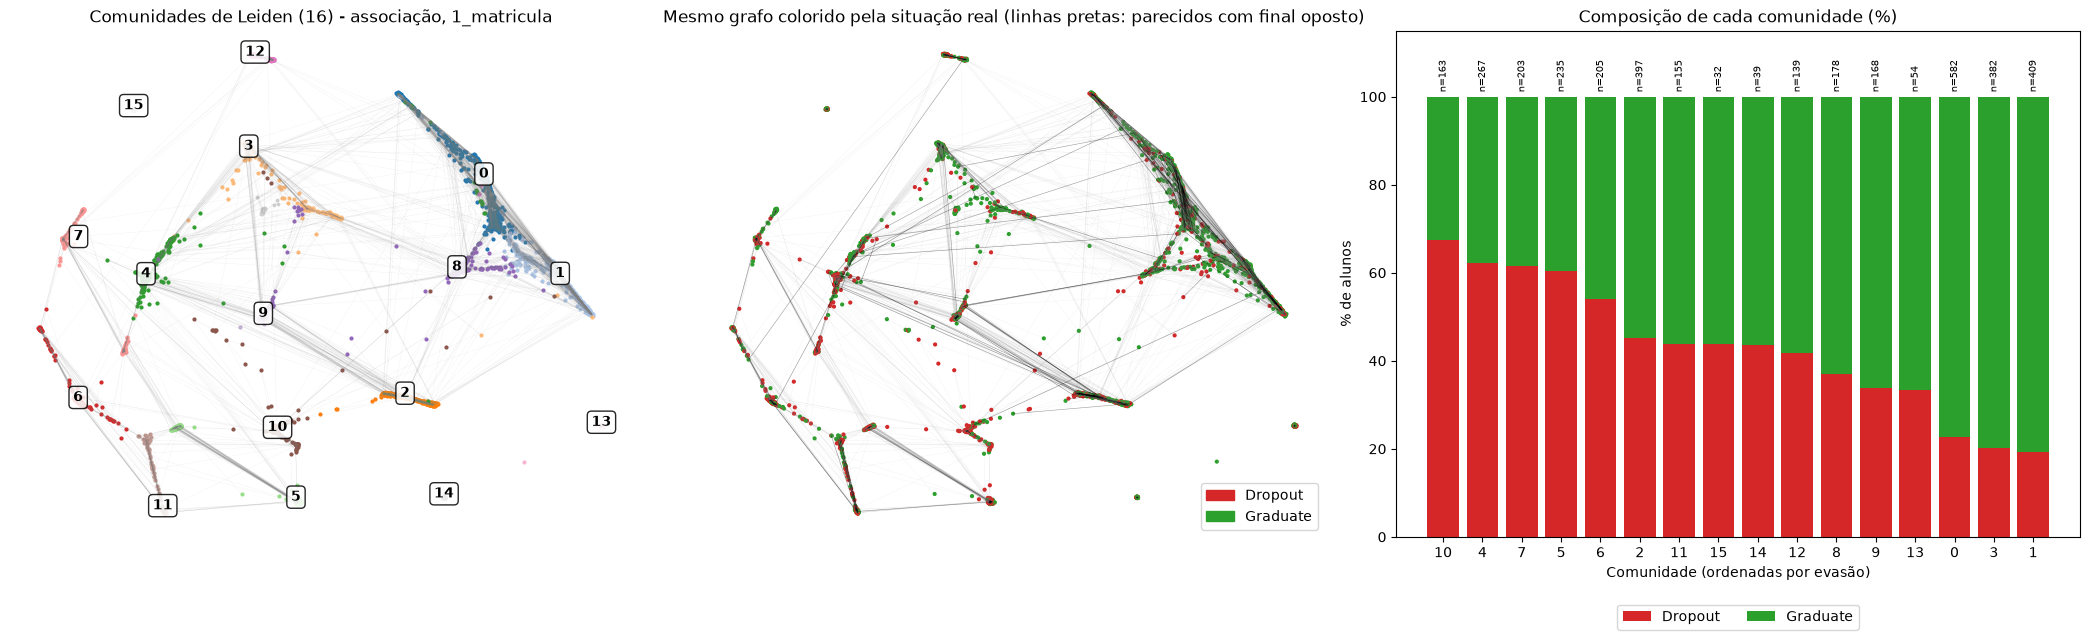

Legenda das comunidades (1_matricula), da maior para a menor evasão:


,comunidade,alunos,evasao,o que caracteriza (traço mais marcante)
0,10,163,67%,Escolaridade do pai=34 (62%)
1,4,267,62%,Modo de ingresso=39 (57%)
2,7,203,62%,Deslocado=0 (66%)
3,5,235,60%,Estado civil=2 (74%)
4,6,205,54%,"Turno (1=diurno, 0=noturno)=0 (100%)"
5,2,397,45%,Gênero=1 (100%)
6,11,155,44%,"Turno (1=diurno, 0=noturno)=0 (100%)"
7,15,32,44%,Nacionalidade=41 (100%)
8,14,39,44%,Necessidades especiais=1 (100%)
9,12,139,42%,Qualificação anterior=39 (99%)


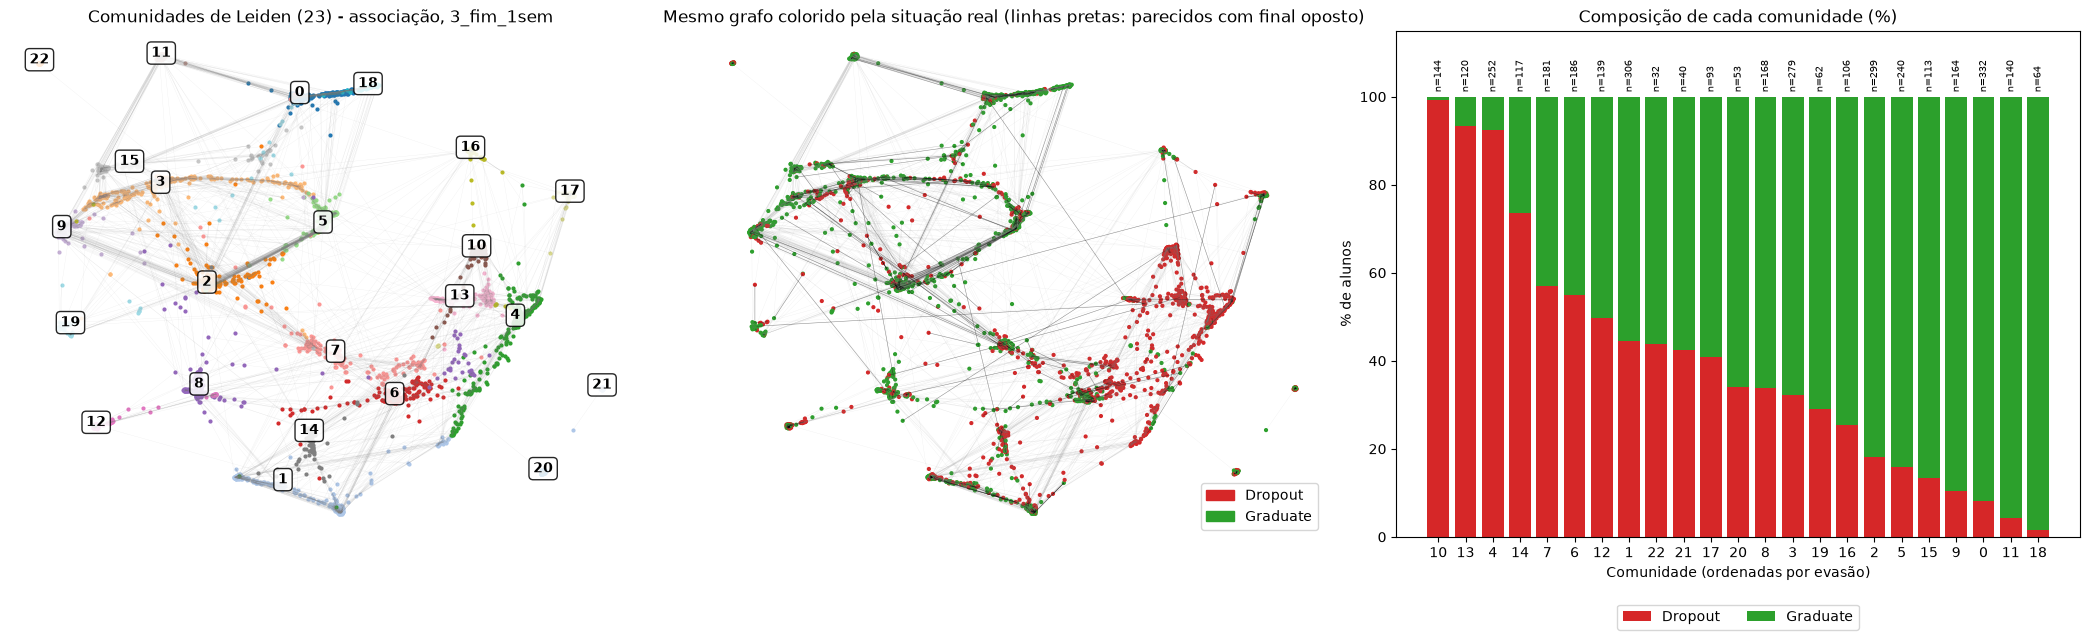

Legenda das comunidades (3_fim_1sem), da maior para a menor evasão:


,comunidade,alunos,evasao,o que caracteriza (traço mais marcante)
0,10,144,99%,1º sem: nota média -2.1dp
1,13,120,93%,Mensalidade em dia=0 (99%)
2,4,252,92%,Devedor=1 (96%)
3,14,117,74%,Escolaridade do pai=34 (79%)
4,7,181,57%,Modo de ingresso=39 (64%)
5,6,186,55%,Estado civil=2 (78%)
6,12,139,50%,1º sem: unid. inscritas -2.5dp
7,1,306,44%,"Turno (1=diurno, 0=noturno)=0 (100%)"
8,22,32,44%,Nacionalidade=41 (100%)
9,21,40,42%,Necessidades especiais=1 (100%)


In [23]:
import random
from matplotlib.collections import LineCollection
LAYOUT = "drl"        # "drl" (igraph, sem dependência extra), "tsne" (scikit-learn) ou "umap" (precisa de umap-learn)
from matplotlib.patches import Patch
COR = np.array(["#d62728", "#2ca02c"]) if NCLS == 2 else np.array(["#d62728", "#f1c40f", "#2ca02c"])

def figura_grafo(jan, minimo=30):
    memb = RES_A[jan]["memb"]; i, j = RES_A[jan]["edges"]; arq = f"cache/pos_{LAYOUT}_{TAG}_{jan}.npy"
    if os.path.exists(arq): emb = np.load(arq)
    else:
        if LAYOUT == "drl":
            g_ = grafo(N, i, j, peso(DIST_ASSOC[jan], i, j)); random.seed(SEED); emb = np.array(g_.layout_drl(weights="weight").coords)
        elif LAYOUT == "tsne":
            from sklearn.manifold import TSNE
            emb = TSNE(metric="precomputed", init="random", random_state=SEED, perplexity=30).fit_transform(DIST_ASSOC[jan].astype(np.float64))
        else:
            import umap; emb = umap.UMAP(metric="precomputed", n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(DIST_ASSOC[jan].astype(np.float64))
        np.save(arq, emb)
    tam = np.bincount(memb); grandes = [c for c in np.argsort(-tam) if tam[c] >= minimo]; cmap = plt.get_cmap("tab20")
    sel = np.random.default_rng(SEED).choice(len(i), min(15000, len(i)), replace=False); seg = np.stack([emb[i[sel]], emb[j[sel]]], 1)
    fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    for a in ax[:2]: a.add_collection(LineCollection(seg, colors="gray", linewidths=.2, alpha=.15)); a.set_axis_off()
    ax[0].scatter(*emb[~np.isin(memb, grandes)].T, s=3, color="lightgray")
    rotulos = {c: rotulo_curto(memb, jan, c, minimo) for c in grandes}
    for k, c in enumerate(grandes):
        m = memb == c; ax[0].scatter(*emb[m].T, s=4, color=cmap(k % 20)); cx, cy = np.median(emb[m], 0)
        ax[0].text(cx, cy, str(c), fontsize=10, weight="bold", ha="center", bbox=dict(boxstyle="round", fc="white", alpha=.85))
    ax[0].set_title(f"Comunidades de Leiden ({len(grandes)}) - associação, {jan}")
    ax[1].scatter(*emb.T, c=COR[y], s=4); ax[1].set_title("Mesmo grafo colorido pela situação real (linhas pretas: parecidos com final oposto)")
    disc = np.where(np.isin(y[i], [0, GRAD]) & np.isin(y[j], [0, GRAD]) & (y[i] != y[j]))[0]
    disc = np.random.default_rng(SEED).choice(disc, min(800, len(disc)), replace=False)
    ax[1].add_collection(LineCollection(np.stack([emb[i[disc]], emb[j[disc]]], 1), colors="black", linewidths=.4, alpha=.4, zorder=3))
    ax[1].legend(handles=[Patch(color=COR[c], label=CLASSES[c]) for c in range(NCLS)], loc="lower right")
    for a in ax[:2]: a.autoscale()
    ordem = sorted(grandes, key=lambda c: -(y[memb == c] == 0).mean()); x = np.arange(len(ordem)); base = np.zeros(len(ordem))
    for c in range(NCLS):
        v = np.array([100 * (y[memb == o] == c).mean() for o in ordem]); ax[2].bar(x, v, bottom=base, color=COR[c], label=CLASSES[c]); base += v
    for xi, o in zip(x, ordem): ax[2].text(xi, 101, f"n={tam[o]}", ha="center", va="bottom", rotation=90, fontsize=7)
    ax[2].set_xticks(x); ax[2].set_xticklabels(ordem); ax[2].set_xlabel("Comunidade (ordenadas por evasão)"); ax[2].set_ylabel("% de alunos"); ax[2].set_ylim(0, 115)
    ax[2].set_title("Composição de cada comunidade (%)"); ax[2].legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=NCLS)
    plt.tight_layout(); plt.savefig(f"figs/var3_grafo_comunidades_{jan}.png", dpi=150); plt.show()

    leg = pd.DataFrame({"comunidade": ordem, "alunos": [tam[o] for o in ordem],
                        "evasao": [f"{(y[memb == o] == 0).mean():.0%}" for o in ordem],
                        "o que caracteriza (traço mais marcante)": [rotulos[o] for o in ordem]})
    print(f"Legenda das comunidades ({jan}), da maior para a menor evasão:"); display(leg)
    leg.to_csv(f"resultados/var3_legenda_comunidades_{jan}.csv", index=False)
    comp = pd.DataFrame({"comunidade": np.arange(len(tam)), **{CLASSES[c]: np.bincount(memb[y == c], minlength=len(tam)) for c in range(NCLS)}, "tamanho": tam})
    comp.to_csv(f"resultados/var3_composicao_{jan}.csv", index=False)
    pd.DataFrame({"aluno": np.arange(N), "comunidade": memb, "situacao": [CLASSES[v] for v in y]}).to_csv(f"resultados/var3_comunidade_por_aluno_{jan}.csv", index=False)

for jan in ["1_matricula", "3_fim_1sem"]: figura_grafo(jan)

### Características mais associadas a Dropout e a Graduate
Para cada **item** (uma categoria, ou uma faixa de quartil de uma variável numérica) e para **pares de itens**, calculamos o *lift* = P(desfecho | regra) / P(desfecho). Lift 1 = acaso; lift 2 = o desfecho aparece o dobro do esperado. Só entram regras com ≥ 3% dos alunos, p-valor corrigido por Benjamini-Hochberg < 0,01, e pares só quando somam algo sobre o melhor item isolado (combinação, não fator solto). Isto é **associação, não causa**, e é calculado direto nos dados (não depende da distância); é o primeiro passo do Grafo 2 do documento.

In [24]:
from scipy.stats import binom

def itens(cats, nums, nbins=4, min_sup=0.03):
    """Transforma cada categoria (var=valor) e cada faixa de quartil de uma variável numérica em um 'item' verdadeiro/falso."""
    cols, nomes = [], []
    for v in cats:
        for val, n in df[v].value_counts().items():
            if n >= min_sup * N: cols.append((df[v] == val).values); nomes.append(f"{v}={val}")
    for v in nums:
        b = pd.qcut(df[v], nbins, duplicates="drop")
        for iv in b.cat.categories:
            m = (b == iv).values
            if m.sum() >= min_sup * N: cols.append(m); nomes.append(f"{v} em [{iv.left:.1f}; {iv.right:.1f}]")
    return np.array(cols).T, np.array(nomes)

def bh(p):                                           # correção de Benjamini-Hochberg
    p = np.asarray(p); o = np.argsort(p); q = np.empty_like(p); m = len(p)
    q[o] = np.minimum.accumulate((p[o] * m / (np.arange(m) + 1))[::-1])[::-1]; return np.minimum(q, 1)

def regras_lift(alvo, cats, nums, classe, min_sup=0.03, ganho_min=0.05, topo=8):
    """Itens isolados e pares de itens mais associados a `classe` (lift = P(classe | regra) / P(classe)).
    Pares só entram se somam pelo menos `ganho_min` de lift sobre o melhor item isolado (combinação, não fator solto)."""
    A, nomes = itens(cats, nums, min_sup=min_sup); A = A.astype(np.float32)
    t = (np.asarray(alvo) == classe).astype(np.float32); base = t.mean()
    S, T = A.sum(0), A.T @ t; lift1 = (T / S) / base
    n2 = A.T @ A; t2 = A.T @ (A * t[:, None])
    ii, jj = np.where(np.triu(n2 >= min_sup * N, 1))
    rows = [(nomes[i], S[i], T[i], lift1[i], 0.0) for i in range(len(nomes))]
    for i, j in zip(ii, jj):
        l = (t2[i, j] / n2[i, j]) / base; g = l - max(lift1[i], lift1[j])
        if g >= ganho_min: rows.append((nomes[i] + " E " + nomes[j], n2[i, j], t2[i, j], l, g))
    r = pd.DataFrame(rows, columns=["regra", "n", "n_classe", "lift", "ganho_sobre_item"])
    r["confianca"] = r["n_classe"] / r["n"]; r["suporte"] = r["n"] / N
    r["q_BH"] = bh(binom.sf(r["n_classe"].values - 1, r["n"].values.astype(int), base))
    r = r[(r["q_BH"] < 0.01) & (r["lift"] > 1)].sort_values("lift", ascending=False)
    return r.head(topo).reset_index(drop=True), base

def plota_regras(ax, r, titulo, cor, base):
    if len(r) == 0:
        ax.text(.5, .5, "nenhuma regra passou nos filtros", ha="center"); ax.set_title(titulo, fontsize=10); return
    ax.barh(range(len(r))[::-1], r["lift"], color=cor); ax.set_yticks(range(len(r))[::-1])
    ax.set_yticklabels([rot(x)[:95] for x in r["regra"]], fontsize=8); ax.axvline(1, ls="--", color="k", lw=.8)
    for y_, (l, c, n) in zip(range(len(r))[::-1], zip(r["lift"], r["confianca"], r["n"])):
        ax.text(l, y_, f"  lift {l:.2f} | {c:.0%} | n={int(n)}", va="center", fontsize=8)
    ax.set_xlim(0, max(r["lift"].max() * 1.45, 1.5)); ax.set_title(f"{titulo}  (taxa geral {base:.0%})", fontsize=10)

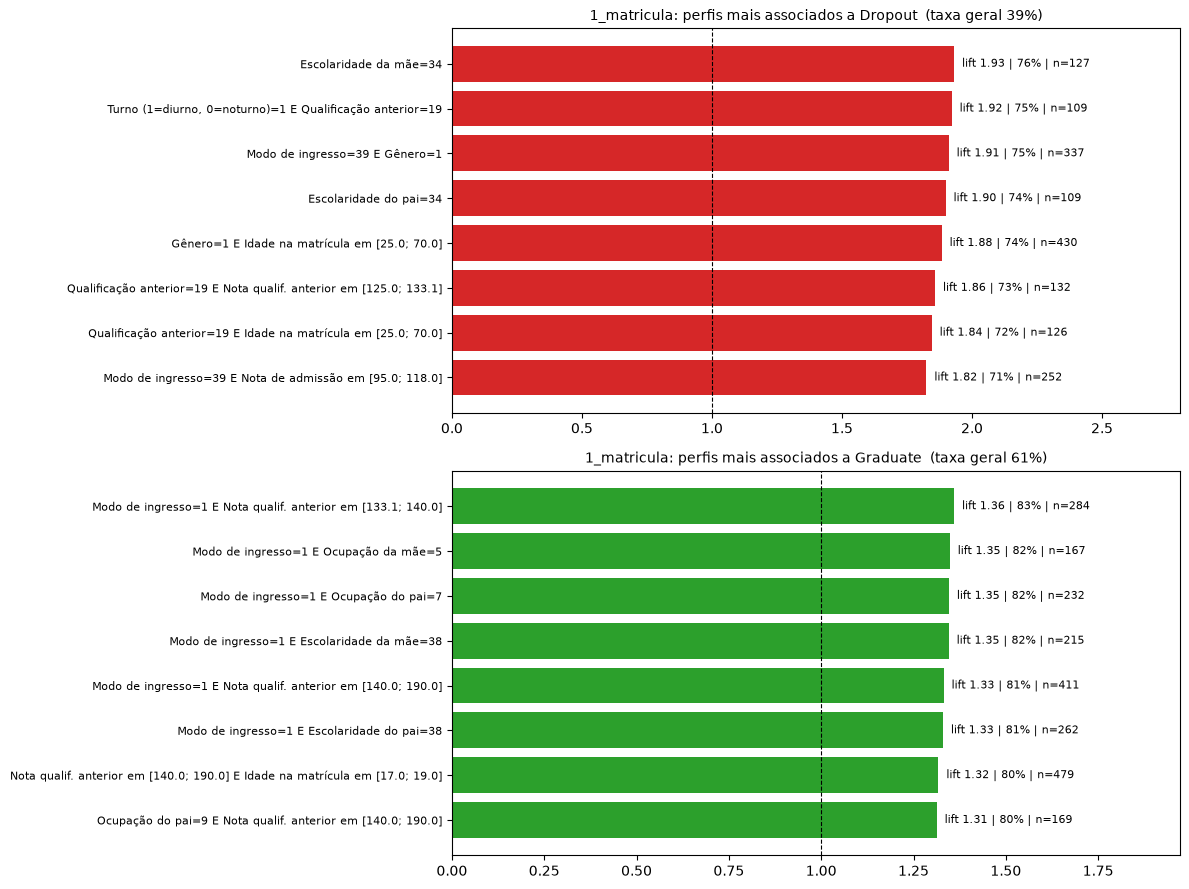

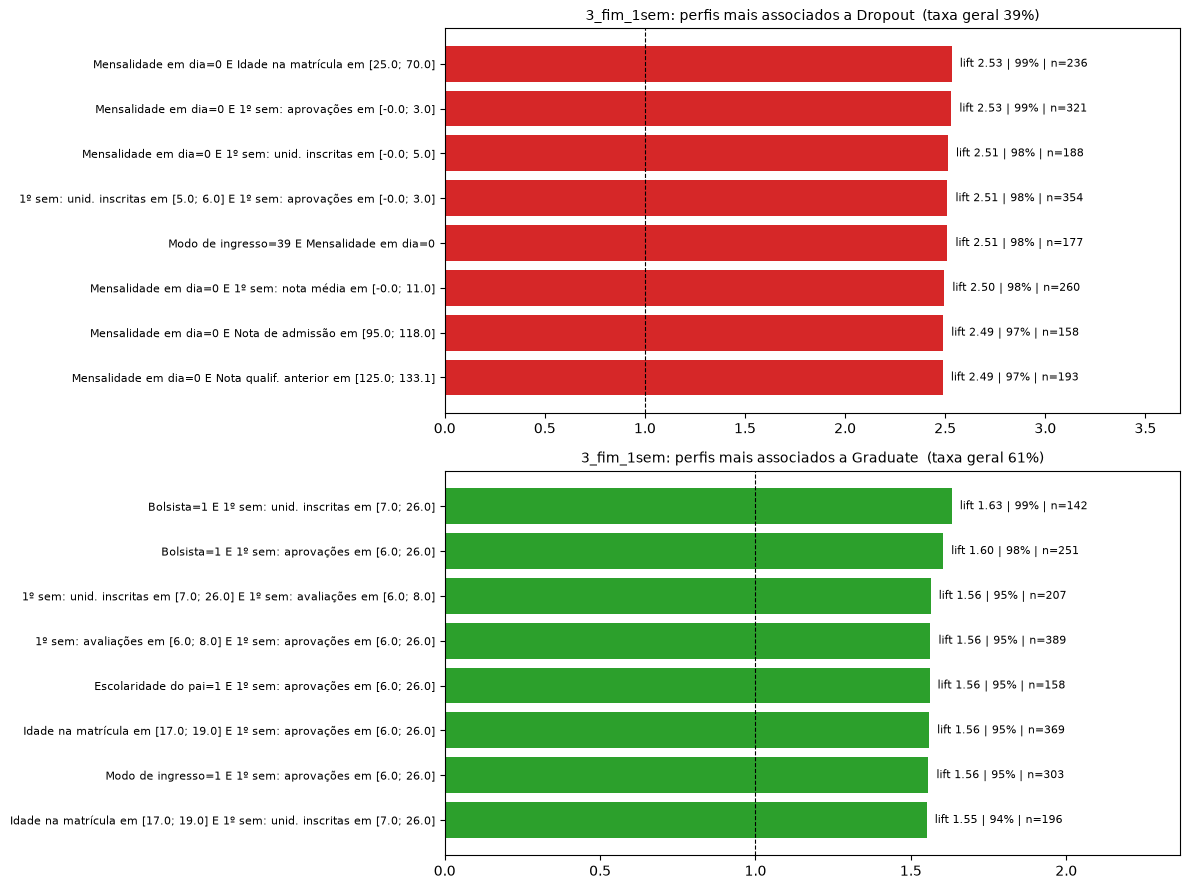

In [25]:
for jan in ["1_matricula", "3_fim_1sem"]:
    cats, nums = JANELAS[jan]; fig, ax = plt.subplots(2, 1, figsize=(12, 9)); saida = []
    for a, (cl, cor, nome) in zip(ax, [(0, "#d62728", "Dropout"), (GRAD, "#2ca02c", "Graduate")]):
        r, base = regras_lift(y, cats, nums, cl); plota_regras(a, r, f"{jan}: perfis mais associados a {nome}", cor, base); r.insert(0, "desfecho", nome); saida.append(r)
    plt.tight_layout(); plt.savefig(f"figs/var3_regras_lift_{jan}.png", dpi=150); plt.show()
    pd.concat(saida).to_csv(f"resultados/var3_regras_lift_{jan}.csv", index=False)

## 8. Alunos parecidos com finais opostos (Grafo 1 com associação)
Fração de alunos que evadiram/formaram cujo vizinho mais parecido teve o final oposto, e quanto cada variável difere nos pares evadiu↔formou em relação aos pares de mesmo final.

,janela,pct_vizinho_oposto,arestas_evadiu_formou,pct_das_arestas
0,1_matricula,37.4,16305,39.0
1,2_financeiro,30.0,6324,30.8
2,3_fim_1sem,20.0,3782,20.5
3,4_fim_2sem,16.9,6969,17.5


,razão (>1 = separa pares opostos)
special_needs,3.87
nationality,3.87
s1_approved,2.17
s1_credited,1.88
s1_grade,1.60
tuition_ok,1.54
scholarship,1.41
s1_without_eval,1.33
s1_enrolled,1.25
s1_evaluations,1.25


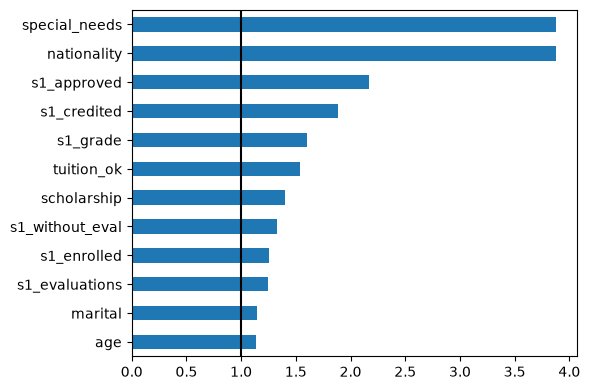

In [26]:
lin = []
for jan in JANELAS:
    D = DIST_ASSOC[jan].copy(); np.fill_diagonal(D, np.inf); nn = D.argmin(1); el = np.isin(y, [0, GRAD])
    op = el & np.isin(y[nn], [0, GRAD]) & (y != y[nn]); i, j = RES_A[jan]["edges"]; mk = np.isin(y[i], [0, GRAD]) & np.isin(y[j], [0, GRAD])
    lin.append(dict(janela=jan, pct_vizinho_oposto=round(100 * op[el].mean(), 1), arestas_evadiu_formou=int(((y[i] != y[j]) & mk).sum()),
                    pct_das_arestas=round(100 * ((y[i] != y[j]) & mk).sum() / len(i), 1)))
op_tab = pd.DataFrame(lin); display(op_tab); op_tab.to_csv("resultados/var3_vizinho_oposto.csv", index=False)

jan = "3_fim_1sem"; cats, nums = JANELAS[jan]; i, j = RES_A[jan]["edges"]; mk = np.isin(y[i], [0, GRAD]) & np.isin(y[j], [0, GRAD])
opo = mk & (y[i] != y[j]); igu = mk & (y[i] == y[j]); razao = {}
for v in nums:
    x = df[v].values.astype(float); razao[v] = np.abs(x[i[opo]] - x[j[opo]]).mean() / max(np.abs(x[i[igu]] - x[j[igu]]).mean(), 1e-9)
for v in cats:
    x = df[v].values; razao[v] = (x[i[opo]] != x[j[opo]]).mean() / max((x[i[igu]] != x[j[igu]]).mean(), 1e-9)
razao = pd.Series(razao).sort_values(ascending=False); display(razao.head(10).round(2).to_frame("razão (>1 = separa pares opostos)"))
razao.head(12).iloc[::-1].plot.barh(figsize=(6, 4)); plt.axvline(1, color="k"); plt.tight_layout(); plt.savefig("figs/var3_pares_opostos.png", dpi=150); plt.show()

## 9. Alunos matriculados (Enrolled): estimativa por comunidade
No modo Dropout × Graduate, os matriculados ficaram fora da modelagem. Aqui cada um é encaixado no grafo **sem usar rótulo**: calculamos a distância por associação até os alunos conhecidos (perfis, frequências e PCA estimados só nos conhecidos), vemos a comunidade mais comum entre seus *k* vizinhos mais parecidos e usamos a **taxa de evasão dessa comunidade** como estimativa.
A tabela de calibração mostra, para os alunos conhecidos (retirando o próprio rótulo da conta), quanto a estimativa se confirma: é ela que sustenta frases como "com X% de certeza". São estimativas por perfil, não garantias individuais.


=== 1_matricula: estimativa (taxa de evasão da comunidade) x evasão real nos alunos conhecidos ===


,alunos,evasao_real
faixa,,
"(-0.001, 0.2]",486,0.321
"(0.2, 0.4]",1287,0.212
"(0.4, 0.6]",967,0.462
"(0.6, 0.8]",868,0.626


classificacao
indefinido            474
provável conclusão    320

=== 3_fim_1sem: estimativa (taxa de evasão da comunidade) x evasão real nos alunos conhecidos ===


,alunos,evasao_real
faixa,,
"(-0.001, 0.2]",1352,0.117
"(0.2, 0.4]",668,0.314
"(0.4, 0.6]",977,0.490
"(0.6, 0.8]",117,0.735
"(0.8, 1.0]",516,0.946


classificacao
indefinido            371
provável conclusão    369
provável evasão        54


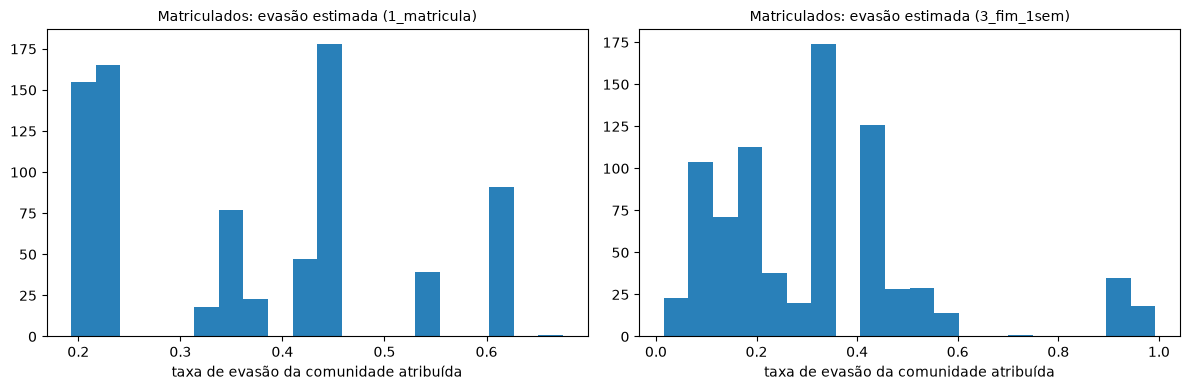

In [27]:
if not SO_DROPOUT_GRADUATE or df_enr is None:
    print("Modo de 3 classes: os 'Enrolled' já são uma classe da análise. Esta seção só vale com SO_DROPOUT_GRADUATE = True.")
else:
    df_all = pd.concat([df, df_enr], ignore_index=True); n_lab = N; fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for ax_, jan in zip(axs, ["1_matricula", "3_fim_1sem"]):
        cats, nums = JANELAS[jan]; memb = RES_A[jan]["memb"]; k = K_A[jan]
        Dall = associacao(cats, nums, ref=np.arange(n_lab), d=df_all)[0]; De = Dall[n_lab:, :n_lab]
        viz = np.argpartition(De, k, axis=1)[:, :k]
        com = np.array([np.bincount(memb[v]).argmax() for v in viz])
        tam = np.bincount(memb); drop_c = np.bincount(memb[y == 0], minlength=len(tam))
        p_com = drop_c[com] / tam[com]; p_viz = (y[viz] == 0).mean(1)
        p_loo = (drop_c[memb] - (y == 0)) / np.maximum(tam[memb] - 1, 1); okc = tam[memb] >= 30     # leave-one-out nos conhecidos
        cal = pd.DataFrame({"faixa": pd.cut(p_loo[okc], [0, .2, .4, .6, .8, 1.0], include_lowest=True), "evadiu": (y[okc] == 0)}).groupby("faixa").agg(
            alunos=("evadiu", "size"), evasao_real=("evadiu", "mean")).round(3)
        print(f"\n=== {jan}: estimativa (taxa de evasão da comunidade) x evasão real nos alunos conhecidos ==="); display(cal)
        classe = np.where(tam[com] < 30, "indefinido", np.where(p_com >= .7, "provável evasão", np.where(p_com <= .3, "provável conclusão", "indefinido")))
        out = pd.DataFrame({"aluno_matriculado": np.arange(len(df_enr)), "comunidade": com, "p_evasao_comunidade": p_com.round(3), "p_evasao_vizinhos": p_viz.round(3), "classificacao": classe})
        out.to_csv(f"resultados/var3_matriculados_{jan}.csv", index=False); print(out["classificacao"].value_counts().to_string())
        ax_.hist(p_com, bins=20, color="#2980b9"); ax_.set_title(f"Matriculados: evasão estimada ({jan})", fontsize=10); ax_.set_xlabel("taxa de evasão da comunidade atribuída")
    plt.tight_layout(); plt.savefig("figs/var3_matriculados.png", dpi=150); plt.show()

## 10. (Opcional) Comparação com Gower + Leiden (variação 1)
Mude `COMPARAR_GOWER = True` na célula de configuração e rode esta célula para ter o mesmo pipeline com Gower (leva mais ~20 min). Ela calcula as métricas e o ARI entre as partições das duas distâncias, que é o que mostra se os perfis dependem da escolha da distância.

In [28]:
if COMPARAR_GOWER:
    DIST_G = carrega("gower", gower); EST_G = escolhe_k(DIST_G, "gower")
    K_G = {jan: int(t.loc[t["media"].idxmax(), "k"]) for jan, t in EST_G.items()}; RES_G = roda(DIST_G, K_G, "gower")
    tab_g = pd.DataFrame({jan: r["metricas"] for jan, r in RES_G.items()}).T
    comp = pd.concat({"Gower": tab_g, "Associação": tab}, axis=1)[[("Gower", c) for c in ["k", "comunidades_ge30", "modularidade", "NMI_ajustado", "V_Cramer", "assortatividade", "estabilidade_ARI"]] +
                                                                     [("Associação", c) for c in ["k", "comunidades_ge30", "modularidade", "NMI_ajustado", "V_Cramer", "assortatividade", "estabilidade_ARI"]]]
    display(comp.round(3)); comp.to_csv("resultados/var3_comparacao_gower.csv")
    print("ARI entre partições Gower × Associação:", {jan: round(ARI(RES_G[jan]["memb"], RES_A[jan]["memb"]), 2) for jan in JANELAS})
else:
    print("Comparação desativada (COMPARAR_GOWER = False).")

gower 1_matricula 1s
gower 2_financeiro 1s
gower 3_fim_1sem 1s
gower 4_fim_2sem 1s
gower 1_matricula 34s
gower 2_financeiro 40s
gower 3_fim_1sem 43s
gower 4_fim_2sem 42s
gower 1_matricula 27s
gower 2_financeiro 30s
gower 3_fim_1sem 30s
gower 4_fim_2sem 25s


Gower                                                      \
                 k comunidades_ge30 modularidade NMI_ajustado V_Cramer   
1_matricula   50.0             10.0        0.661        0.035    0.320   
2_financeiro  50.0             10.0        0.632        0.066    0.423   
3_fim_1sem    40.0             12.0        0.651        0.086    0.494   
4_fim_2sem    15.0             18.0        0.750        0.108    0.589   

                                              Associação                   \
             assortatividade estabilidade_ARI          k comunidades_ge30   
1_matricula            0.158            0.879       40.0             16.0   
2_financeiro           0.272            0.848       20.0             22.0   
3_fim_1sem             0.407            0.765       20.0             23.0   
4_fim_2sem             0.545            0.883       50.0             14.0   

                                                                 \
             modularidade NMI_ajustado V_Cramer assortatividade   
1_matricula         0.841        0.036    0.343           0.166   
2_financeiro        0.889        0.081    0.522           0.345   
3_fim_1sem          0.858        0.105    0.585           0.552   
4_fim_2sem          0.773        0.137    0.617           0.606   

                               
             estabilidade_ARI  
1_matricula             0.978  
2_financeiro            0.991  
3_fim_1sem              0.938  
4_fim_2sem              0.890

ARI entre partições Gower × Associação: {'1_matricula': 0.35, '2_financeiro': 0.29, '3_fim_1sem': 0.3, '4_fim_2sem': 0.23}


## 11. Como ler e escrever no artigo
* **Separação ≠ qualidade.** A associação dá mais peso a variáveis raras/ligadas ao desfecho (turno, dívida, mensalidade, gênero); parte da separação maior pode vir de ter **mais comunidades**. Reporte o NMI ajustado (subtrai o acaso) e comente isso.
* **Estabilidade:** reporte o ARI entre consensos e o fato de k ter ficado no limite da faixa, se for o caso.
* **Risco na matrícula:** veja se as comunidades de alto risco (evasão ≥ 50%) aparecem com o mesmo perfil (mais velhos, ingresso "maiores de 23", pais com escolaridade desconhecida) — esse é o achado que deve ser robusto à escolha da distância.
* **Fim do 1º semestre:** comunidades extremas (ex.: 100% de evasão) tendem a descrever alunos que **já estão saindo**, não risco a antecipar.
* Lembrar: *associação não é causa*; "Enrolled" = atraso; transferência conta como evasão; perfil de risco serve para oferecer apoio, nunca para rotular.
* Referência do documento do grupo (associação + Leiden): na matrícula ~19 comunidades ≥30 e V de Cramér ≈ 0,27; no 1º semestre ~32 comunidades e V ≈ 0,43; ARI Gower×associação entre 0,27 e 0,43. Pequenas diferenças são normais (a escolha do k e o consenso mudam algo).

Arquivos gerados: `resultados/var3_*.csv`, `figs/var3_*.png` e `cache/` (distâncias e etapas pesadas — apague para refazer do zero).